c:\Users\ksaij\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


=== SUPPORT VECTOR MACHINE (SVM) RESULTS ===
Accuracy : 0.9953
Precision: 0.9963
Recall   : 0.9853
F1-Score : 0.9908

Classification Report:
               precision    recall  f1-score   support

   White (0)       0.99      1.00      1.00       792
     Red (1)       1.00      0.99      0.99       272

    accuracy                           1.00      1064
   macro avg       1.00      0.99      0.99      1064
weighted avg       1.00      1.00      1.00      1064



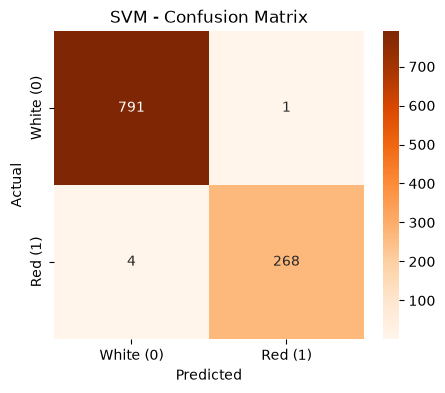

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# 1. Load Preprocessed Datasets
X_train = pd.read_csv("X_train_processed.csv")
X_test = pd.read_csv("X_test_processed.csv")
y_train = pd.read_csv("y_train.csv").values.ravel()
y_test = pd.read_csv("y_test.csv").values.ravel()

# 2. Train Support Vector Classifier (RBF Kernel)
svm_model = SVC(kernel='rbf', C=1.0, probability=True, random_state=42)
svm_model.fit(X_train, y_train)

# 3. Predict & Evaluate
y_pred_svm = svm_model.predict(X_test)

print("=== SUPPORT VECTOR MACHINE (SVM) RESULTS ===")
print(f"Accuracy : {accuracy_score(y_test, y_pred_svm):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_svm):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_svm):.4f}")
print(f"F1-Score : {f1_score(y_test, y_pred_svm):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred_svm, target_names=['White (0)', 'Red (1)']))

# 4. Confusion Matrix Heatmap
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_svm), annot=True, fmt='d', cmap='Oranges', 
            xticklabels=['White (0)', 'Red (1)'], yticklabels=['White (0)', 'Red (1)'])
plt.title("SVM - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()